# 01b · Linking PitchAPI players to FPL players

**Why:** to re-score 2021-22 → 2024-25 under today's rules we need each player's defensive actions, which only
PitchAPI has for those seasons. That only works if every PitchAPI player is linked to the **right** FPL player.

**How it works** ([`fpl_engine/matching.py`](../fpl_engine/matching.py)):
1. **Teams.** A PitchAPI team and an FPL team that played on the same dates (home/away) are the same club. No names needed.
2. **Fixtures.** Same season + same home club + same away club.
3. **Players.** A PitchAPI player is only compared with FPL players **in the same team in the same match**. Each pair gets:
   - a **name score**: accents, case and punctuation ignored, compared against FPL's full name, display name and reversed name.
     A first name alone never counts ("Jack Jenkins" ≠ "Jack Harrison").
   - a **stats-agreement rate**: across every match they shared, did both sources agree on *whether he played*,
     *how many goals*, and *minutes (±2)*?
4. **Tiers.**

| Tier | Rule | Used? |
|---|---|---|
| A · exact name | normalised names identical, and stats agree ≥ 90% (or he never played) | ✅ |
| B · fuzzy name + stats | name score ≥ 80 and stats agree ≥ 90% | ✅ |
| C · stats only | names differ but stats agree ≥ 90% over 5+ matches | review |
| D · review | anything else | review |
| M · manual | your overrides in `config/manual_player_mappings.csv` (always win) | ✅ |

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore', message='pandas only supports SQLAlchemy')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from fpl_engine import db, matching
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_rows', 100, 'display.width', 200)
conn = db.connect()
r = matching.run(conn, write=False)
teams, fx, ev, d = r['teams'], r['fixtures'], r['evidence'], r['decisions']
d['accepted'] = d.tier.isin(matching.ACCEPT) & ~d.conflict.fillna(False).astype(bool)

## 1 · Teams and fixtures

In [2]:
names = pd.read_sql('SELECT team_id, team_name FROM core.teams', conn).set_index('team_id').team_name
print(f"{len(teams)} PitchAPI team-seasons mapped; lowest date-overlap {teams.confidence.min():.0%}, "
      f"highest runner-up {teams.runner_up.max():.0%}")
print(f"{fx.fixture_id.notna().sum()} of {len(fx)} finished PitchAPI matches linked to an FPL fixture")
teams.assign(fpl_name=teams.team_id.map(names)).drop_duplicates(['team_name', 'team_id'])[['team_name', 'fpl_name']].sort_values('team_name').reset_index(drop=True).T

120 PitchAPI team-seasons mapped; lowest date-overlap 100%, highest runner-up 82%
2009 of 2009 finished PitchAPI matches linked to an FPL fixture


,0,1,2,3,4,5,6,7,8,9,...,19,20,21,22,23,24,25,26,27,28
team_name,AFC Bournemouth,Arsenal,Aston Villa,Brentford,Brighton & Hove Albion,Burnley,Chelsea,Coventry City,Crystal Palace,Everton,...,Newcastle United,Norwich City,Nottingham Forest,Sheffield United,Southampton,Sunderland,Tottenham Hotspur,Watford,West Ham United,Wolverhampton Wanderers
fpl_name,Bournemouth,Arsenal,Aston Villa,Brentford,Brighton,Burnley,Chelsea,Coventry City,Crystal Palace,Everton,...,Newcastle,Norwich,Nott'm Forest,Sheffield Utd,Southampton,Sunderland,Spurs,Watford,West Ham,Wolves


Every PitchAPI club lines up with its FPL club on **100%** of its match dates, with no close runner-up. All 2,009
finished matches link to an FPL fixture.

## 2 · Players: the headline numbers

In [3]:
summary = pd.DataFrame({
    'players': d.groupby('tier').size(),
    'share %': (d.groupby('tier').size() / len(d) * 100).round(1)})
summary.loc['TOTAL accepted'] = [d.accepted.sum(), round(100 * d.accepted.mean(), 1)]
summary

,players,share %
tier,,
A_exact_name,1685,95.0
B_fuzzy_name_stats,60,3.4
M_manual,26,1.5
X_manual_unmatched,2,0.1
TOTAL accepted,1771,99.9


Exact normalised-name matches: 95.1% of accepted players
Accepted players who played at least once in a shared match: 1358 (76.7%)
  ...median shared appearances: 28; stats agreement: median 100.0%, 5th percentile 100.0%, minimum 90.0%


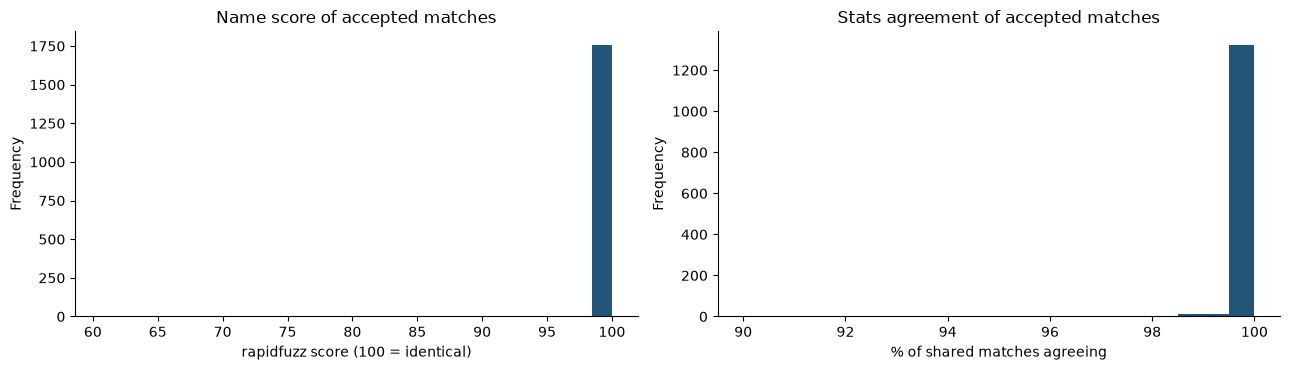

In [4]:
acc = d[d.accepted]
print(f"Exact normalised-name matches: {acc.name_exact.mean():.1%} of accepted players")
print(f"Accepted players who played at least once in a shared match: {(acc.either_played > 0).sum()} "
      f"({(acc.either_played > 0).mean():.1%})")
played = acc[acc.either_played > 0]
print(f"  ...median shared appearances: {played.either_played.median():.0f}; "
      f"stats agreement: median {played.agree_rate.median():.1%}, 5th percentile {played.agree_rate.quantile(.05):.1%}, "
      f"minimum {played.agree_rate.min():.1%}")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
acc.name_score.clip(50, 100).plot.hist(bins=26, ax=axes[0], color='#257')
axes[0].set_title('Name score of accepted matches'); axes[0].set_xlabel('rapidfuzz score (100 = identical)')
played.agree_rate.mul(100).clip(80, 100).plot.hist(bins=20, ax=axes[1], color='#257')
axes[1].set_title('Stats agreement of accepted matches'); axes[1].set_xlabel('% of shared matches agreeing')
plt.tight_layout(); plt.show()

### How sure is "stats agreement"?
A false match would need two *different* players on the same team to agree on whether they played, their goals and
their minutes in match after match. For comparison, here's how much the **runner-up candidate** (the next-best FPL
player in the same squad) agrees with each PitchAPI player:

In [5]:
ev_sorted = ev.sort_values(['pid', 'score'], ascending=[True, False])
runner = ev_sorted.groupby('pid').nth(1).set_index('pid')
cmp = pd.DataFrame({'best match': d.set_index('pid').loc[acc.pid, 'agree_rate'],
                    'runner-up': runner.agree_rate.reindex(acc.pid)}).dropna()
cmp.describe().loc[['mean', '50%', 'max']].mul(100).round(1)

,best match,runner-up
mean,99.9,39.5
50%,100.0,34.2
max,100.0,100.0


The best match agrees almost always; the runner-up agrees rarely, and only by coincidence (e.g. both were unused
subs that day). That separation is what makes stats evidence much stronger than names alone.

## 3 · The fuzzy-name matches (tier B): eyeball these

In [6]:
cols = ['pa_name', 'first_name', 'second_name', 'web_name', 'position', 'name_score', 'agree_rate', 'both_played', 'seasons']
d[d.tier == 'B_fuzzy_name_stats'].sort_values('name_score')[cols].reset_index(drop=True)

,pa_name,first_name,second_name,web_name,position,name_score,agree_rate,both_played,seasons
0,Jaden Philogene-Bidace,Jaden,Philogene,Philogene,MID,81.081081,1.0,29.0,"2021-22,2023-24,2024-25,2026-27"
1,Diogo Jota,Diogo,Teixeira da Silva,Diogo J.,MID,82.352941,1.0,104.0,"2021-22,2022-23,2023-24,2024-25"
2,Arnaud Kalimuendo-Muinga,Arnaud,Kalimuendo,Kalimuendo,FWD,82.926829,1.0,13.0,"2025-26,2026-27"
3,Emerson Royal,Emerson,Leite de Souza Junior,E.Royal,DEF,83.333333,1.0,79.0,"2021-22,2022-23,2023-24"
4,Alysson Edward,Alysson Edward Franco,da Rocha dos Santos,Alysson,MID,83.333333,1.0,13.0,"2025-26,2026-27"
5,Rodri,Rodrigo 'Rodri',Hernandez Cascante,Rodrigo,MID,83.333333,1.0,127.0,"2021-22,2022-23,2023-24,2024-25,2025-26"
6,Lucas Paquetá,Lucas,Tolentino Coelho de Lima,L.Paquetá,MID,87.500000,1.0,110.0,"2022-23,2023-24,2024-25,2025-26"
7,Timur Tuterov,Tymur,Tutierov,Tutierov,MID,88.888889,1.0,2.0,"2025-26,2026-27"
8,Yéremi Pino,Yéremy,Pino Santos,Yeremy,MID,90.909091,1.0,45.0,"2025-26,2026-27"
9,Przemysław Płacheta,Przemyslaw,Placheta,Placheta,MID,94.444444,1.0,12.0,2021-22


## 4 · Independent check: do linked players' defensive counts equal FPL's?

In **2025-26 and 2026-27**, FPL publishes each player's defensive-contribution count itself. If the linking is right,
PitchAPI's count for the linked player (clearances + blocks + interceptions + tackles, plus recoveries for MID/FWD)
should equal FPL's count in the same match. This checks the linking **and** the back-fill formula at once.

In [7]:
pa = pd.read_sql('''
  SELECT fs.fixture_id, x->'player'->>'id' AS pid,
         sum((e.v->'stat'->>'value')::float) FILTER (WHERE e.k IN ('Clearances','Blocks','Interceptions','Tackles')) AS cbit,
         sum((e.v->'stat'->>'value')::float) FILTER (WHERE e.k = 'Recoveries') AS recoveries
  FROM raw.provider_records r
  JOIN core.fixture_source_ids fs ON fs.source_name = 'pitchapi' AND fs.source_fixture_id = r.entity_id
  CROSS JOIN jsonb_array_elements(r.payload) x
  CROSS JOIN jsonb_array_elements(x->'stats') g
  CROSS JOIN jsonb_each(g->'stats') e(k, v)
  WHERE r.source_name = 'pitchapi' AND r.entity = 'match_players' AND r.season >= '2025-26'
  GROUP BY 1, 2''', conn)
link = pd.read_sql("SELECT source_player_id AS pid, canonical_player_id AS player_id FROM core.player_source_ids WHERE source_name = 'pitchapi'", conn)
fpl = pd.read_sql('''SELECT s.fixture_id, s.player_id, ps.position, s.minutes, s.defensive_contribution
                     FROM core.player_match_stats s JOIN core.player_seasons ps USING (player_id, season)
                     WHERE s.season >= '2025-26' AND s.minutes > 0 AND ps.position IN ('DEF','MID','FWD')''', conn)
x = pa.merge(link, on='pid').merge(fpl, on=['fixture_id', 'player_id'])
x['pa_count'] = np.where(x.position == 'DEF', x.cbit.fillna(0), x.cbit.fillna(0) + x.recoveries.fillna(0))
thr = x.position.map({'DEF': 10, 'MID': 12, 'FWD': 12})
x['pa_hit'], x['fpl_hit'] = x.pa_count >= thr, x.defensive_contribution >= thr
print(f"{len(x):,} player-matches compared (2025-26 onwards, players who played)")
print(f"  count exactly equal:            {(x.pa_count == x.defensive_contribution).mean():.1%}")
print(f"  count within ±1:                {((x.pa_count - x.defensive_contribution).abs() <= 1).mean():.1%}")
print(f"  correlation:                    {np.corrcoef(x.pa_count, x.defensive_contribution)[0, 1]:.3f}")
print(f"  same threshold outcome (2 pts or not): {(x.pa_hit == x.fpl_hit).mean():.2%}")
pd.crosstab(x.fpl_hit, x.pa_hit, rownames=['FPL says 2 pts'], colnames=['PitchAPI says 2 pts'])

13,870 player-matches compared (2025-26 onwards, players who played)
  count exactly equal:            95.5%
  count within ±1:                99.5%
  correlation:                    0.998
  same threshold outcome (2 pts or not): 99.66%


PitchAPI says 2 pts,False,True
FPL says 2 pts,,
False,12044,27
True,20,1779


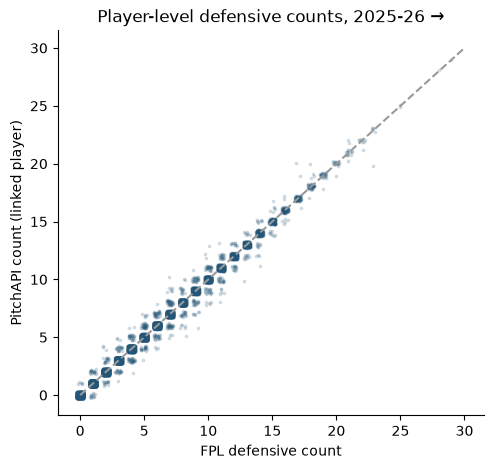

In [8]:
fig, ax = plt.subplots(figsize=(5.5, 5))
j = np.random.default_rng(0).uniform(-.25, .25, (2, len(x)))
ax.scatter(x.defensive_contribution + j[0], x.pa_count + j[1], s=3, alpha=.15, color='#257')
ax.plot([0, 30], [0, 30], '--', color='#999'); ax.set_xlabel('FPL defensive count'); ax.set_ylabel('PitchAPI count (linked player)')
ax.set_title('Player-level defensive counts, 2025-26 →'); plt.show()

## 5 · Coverage where it matters: 2021-22 → 2024-25

What share of FPL **minutes** in the back-fill seasons belongs to a linked player? (Unlinked players are mostly
youngsters who never played.)

In [9]:
cov = pd.read_sql('''
  SELECT s.season, sum(s.minutes) AS minutes,
         sum(s.minutes) FILTER (WHERE EXISTS (SELECT 1 FROM core.player_source_ids i
              WHERE i.source_name = 'pitchapi' AND i.canonical_player_id = s.player_id)) AS linked_minutes
  FROM core.player_match_stats s WHERE s.season BETWEEN '2021-22' AND '2024-25' GROUP BY 1 ORDER BY 1''', conn)
cov['linked %'] = (100 * cov.linked_minutes / cov.minutes).round(2); cov

,season,minutes,linked_minutes,linked %
0,2021-22,749468,749468,100.0
1,2022-23,749114,749114,100.0
2,2023-24,748630,748630,100.0
3,2024-25,748464,748464,100.0


## 6 · The review list: where I need your help

In [10]:
rv = d[~d.accepted].copy()
rv['why'] = np.select(
    [rv.conflict.fillna(False).astype(bool), rv.either_played.fillna(0) == 0, rv.agree_rate.fillna(0) < 0.5],
    ['two different names claim one FPL player', 'never played in a shared match: name-only evidence',
     'best candidate disagrees on stats: probably not in FPL'], 'stats agree, names differ')
rv['best_fpl_candidate'] = (rv.first_name.fillna('') + ' ' + rv.second_name.fillna('')).str.strip()
rv[['why', 'pid', 'pa_name', 'best_fpl_candidate', 'name_score', 'agree_rate', 'either_played', 'seasons']].sort_values(
    ['why', 'either_played'], ascending=[True, False]).reset_index(drop=True)

,why,pid,pa_name,best_fpl_candidate,name_score,agree_rate,either_played,seasons
0,never played in a shared match: name-only evid...,p_2Gs1MI,Levi Laing,Nikola Vlasic,50.000000,NaN,0.0,2023-24
1,never played in a shared match: name-only evid...,p_4De7ku,Álvaro Carreras,Álvaro Fernández,64.516129,NaN,0.0,"2021-22,2023-24"


**Resolved with you (2026-11-23):** 26 manual links (25 approved rows + William Crellin = Billy Crellin), Levi Laing and
Álvaro Carreras left unlinked as not in FPL. Five academy players (Kadan Young, Tom Taylor, Charlie Robinson, George Shelvey,
Harvey Davies) were initially mis-assigned to a senior namesake. Fixed by counting "both unused on the bench" as agreement.
The review list is now empty.

## 7 · Back-filled defensive counts, and a surprise: stat definitions drift

With players linked, PitchAPI's defensive actions fill 2021-22 → 2024-25 (`core.player_match_defensive`). But league
averages per team-match are **not stable over time**, and FPL's own published numbers (2016-19, 2025-26) show the same
shift. So this is the shared data feed changing definitions, not a PitchAPI problem:

In [11]:
drift = pd.read_sql("SELECT season, stat, season_mean::float, factor::float FROM core.stat_season_adjustments WHERE source='pitchapi'", conn)
drift.pivot(index='season', columns='stat', values='season_mean').round(1)

stat,blocks,clearances,interceptions,recoveries,tackles
season,,,,,
2021-22,3.6,18.5,9.6,60.8,16.3
2022-23,3.5,18.5,8.9,60.3,17.0
2023-24,3.9,19.5,8.3,55.4,17.7
2024-25,3.7,22.9,7.9,48.3,17.6
2025-26,3.6,27.0,8.3,46.8,16.7
2026-27,3.9,25.8,8.8,47.6,15.8


Recoveries fell ~23% and clearances rose ~45% between 2023 and 2025. Left alone, this would make midfielders' older
defensive points look too generous (recoveries count for MID/FWD) and defenders' too stingy (clearances).

**Decision (yours): rescale older seasons to today's definitions.** For each stat and season,
`factor = 2025-26 league average ÷ that season's league average`. Raw counts stay untouched; the adjusted count is in
`core.v_player_match_stats.defensive_contribution_adjusted`, and the factors are in `core.stat_season_adjustments`.

In [12]:
drift.pivot(index='season', columns='stat', values='factor')

stat,blocks,clearances,interceptions,recoveries,tackles
season,,,,,
2021-22,1.0047,1.4593,0.8600,0.7701,1.0213
2022-23,1.0267,1.4555,0.9262,0.7764,0.9817
2023-24,0.9335,1.3867,0.9971,0.8445,0.9442
2024-25,0.9847,1.1779,1.0426,0.9700,0.9476
2025-26,1.0000,1.0000,1.0000,1.0000,1.0000
2026-27,1.0000,1.0000,1.0000,1.0000,1.0000


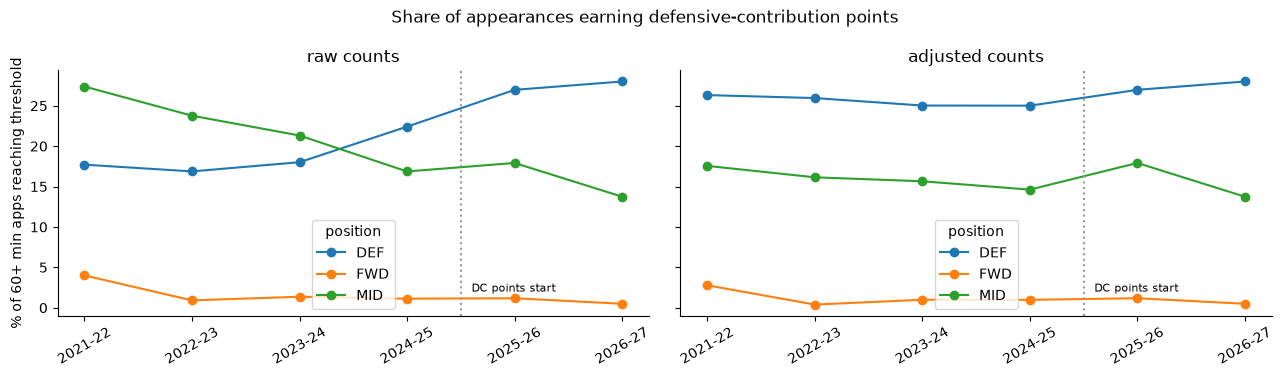

raw            adjusted           
position   DEF  FWD   MID      DEF  FWD   MID
season                                       
2021-22   17.7  4.0  27.4     26.3  2.8  17.6
2022-23   16.9  0.9  23.8     25.9  0.4  16.1
2023-24   18.0  1.4  21.3     25.0  1.0  15.7
2024-25   22.4  1.1  16.9     25.0  1.0  14.6
2025-26   27.0  1.2  17.9     27.0  1.2  17.9
2026-27   28.0  0.5  13.7     28.0  0.5  13.7

In [13]:
v = pd.read_sql("SELECT season, position, minutes, defensive_contribution_filled AS raw, "
                "defensive_contribution_adjusted::float AS adjusted FROM core.v_player_match_stats "
                "WHERE season >= '2021-22' AND minutes >= 60 AND position IN ('DEF','MID','FWD')", conn)
thr = v.position.map({'DEF': 10, 'MID': 12, 'FWD': 12})
hit = pd.concat({k: (v[k] >= thr).groupby([v.season, v.position]).mean().unstack() * 100 for k in ['raw', 'adjusted']}, axis=1)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, k in zip(axes, ['raw', 'adjusted']):
    hit[k].reset_index(drop=True).plot(ax=ax, marker='o'); ax.set_title(f'{k} counts')
    ax.set_xticks(range(len(hit))); ax.set_xticklabels(hit.index, rotation=30)
    ax.set_ylabel('% of 60+ min apps reaching threshold'); ax.axvline(3.5, ls=':', color='#999')
    ax.text(3.6, 2, 'DC points start', fontsize=8)
plt.suptitle('Share of appearances earning defensive-contribution points'); plt.tight_layout(); plt.show()
hit.round(1)

After adjustment the hit rate per position varies by only 3–4 points across seasons (was 11–14). The small remaining
rise for defenders in 2025-26 may be genuine: players responding to the new reward.